In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

dataset = pd.read_csv('hepatitis.csv')
dataBersih = dataset.replace('?', np.nan)
dataBersihNew = dataBersih.dropna()

X = dataBersihNew.iloc[:, [1,2,3,4,5,6,7,8]].values
y = dataBersihNew.iloc[:, 0].values

print("Ukuran dataset setelah bersihin missing value:", X.shape)

Ukuran dataset setelah bersihin missing value: (80, 8)


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 60
Jumlah data testing: 20


In [12]:
from sklearn.neighbors import KNeighborsClassifier

classifier = KNeighborsClassifier(n_neighbors=3, metric='euclidean', p=2)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)
print("Prediksi berhasil dilakukan pada data uji!")

Prediksi berhasil dilakukan pada data uji!


In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

acc = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=2)
recall = recall_score(y_test, y_pred, pos_label=2)
f1 = f1_score(y_test, y_pred, pos_label=2)

print("=== METRIK EVALUASI KNN ===")
print(f"Accuracy  : {acc * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%\n")

print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=['DIE (1)', 'LIVE (2)']))

=== METRIK EVALUASI KNN ===
Accuracy  : 85.00%
Precision : 88.89%
Recall    : 94.12%
F1-Score  : 91.43%

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     DIE (1)       0.50      0.33      0.40         3
    LIVE (2)       0.89      0.94      0.91        17

    accuracy                           0.85        20
   macro avg       0.69      0.64      0.66        20
weighted avg       0.83      0.85      0.84        20



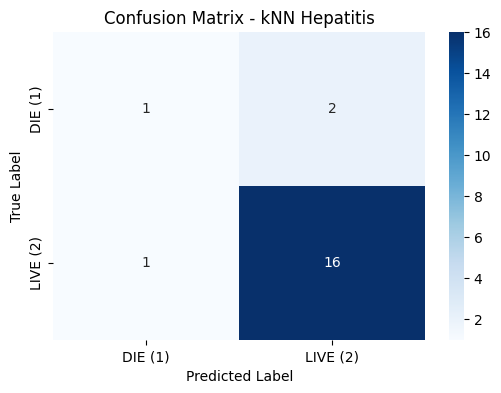

In [15]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['DIE (1)', 'LIVE (2)'],
            yticklabels=['DIE (1)', 'LIVE (2)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - KNN Hepatitis')
plt.show()

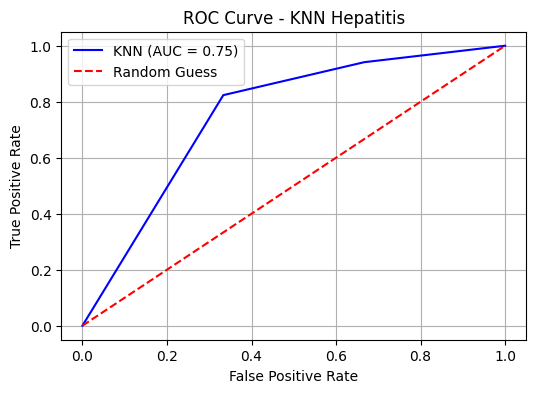

In [16]:
from sklearn.metrics import roc_auc_score, roc_curve

y_proba = classifier.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, y_proba)
fpr, tpr, thresholds = roc_curve(y_test, y_proba, pos_label=2)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='blue', label=f'KNN (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - KNN Hepatitis')
plt.legend()
plt.grid(True)
plt.show()